# Toxic Comment Detection: BiLSTM vs DistilBERT vs BERT vs RoBERTa vs GPT-2
### Multi-epoch, model-by-model comparative case study (Jigsaw Toxic Comment Classification)

**What this notebook does**
- Trains every model for several epochs and records, after **every epoch**, train loss, validation loss, validation and test scores and epoch time (saved to Google Drive).
- Picks each model's **best epoch on the validation set** (macro PR-AUC). Test scores are reported at that epoch, with thresholds tuned on validation.
- **Resumes automatically** after a disconnect, from the last finished epoch.
- Compares all finished models: learning curves, epoch-by-epoch tables, best-epoch table, best vs last epoch, per-label F1, accuracy vs speed.

**Run order**
1. Runtime > Change runtime type > **T4 GPU**.
2. Run Sections 1-6 once per session (about 2 minutes).
3. Recommended: run the **pre-flight check** (Section 6b). It tests every model on one small batch (about 3-5 minutes), so any problem shows up before a long run.
4. Section 7: run **7.0 Train all pending models** (skips finished models, resumes interrupted ones, carries on if one model fails), or run one model cell at a time.
5. Section 8 compares whatever has finished. Section 9 downloads the results. The troubleshooting list is at the end.

**First time? Set `QUICK_TEST = True` in Section 1.** All five models then finish in about 30 minutes (20,000 training comments, 2 epochs each) and save to a separate folder. Use it once to confirm everything works, then switch it back to `False`.
**Full run:** roughly 2.5-3 hours on a T4 in total (estimate), and it can be split over several sessions.

**Warning:** the dataset contains offensive language. Mask examples before putting them in your report.

## 1. Configuration (change only this cell)

In [1]:
SEED = 42
LABELS = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

QUICK_TEST = False       # True = small test run (20,000 training comments, 2 epochs per model, about 30 min for all five models).
                         # It saves to its own folder, so it never mixes with a full run.

MAX_LEN = 128            # transformer tokens per comment
BATCH_SIZE = 32          # transformer training batch size (use 16 if you get an out-of-memory error)
EVAL_BATCH_SIZE = 128
MAX_TRAIN_ROWS = None    # None = full training split (~127k rows). Example: 40000 for a faster run
USE_POS_WEIGHT = True    # class weighting for the rare labels (threat, identity_hate)
USE_AMP = True           # fp16 mixed precision on the GPU (set False if a transformer's loss turns to nan)

USE_DRIVE = True         # save everything to Google Drive so separate sessions can share results
SAVE_CHECKPOINTS = True  # resume after a disconnect (needs ~1.5 GB free Drive space while a transformer trains)
PATIENCE = None          # None = train every epoch. Example: 2 = stop after 2 epochs without validation improvement
SELECT_METRIC = "val_macro_pr_auc"   # how the best epoch is chosen (threshold-free, validation only)
FORCE_RETRAIN = False    # True = ignore finished results for a model and train it again
USE_GITHUB_MIRROR = True # if train.csv is not found, try an unofficial public copy of Kaggle's file (always validated)

# Epochs and learning rate per model. Change epochs here to train for longer.
MODEL_REGISTRY = {
    "BiLSTM":     dict(kind="lstm", epochs=3, lr=1e-3, batch_size=128),
    "DistilBERT": dict(kind="hf", checkpoint="distilbert-base-uncased", epochs=3, lr=3e-5),
    "BERT":       dict(kind="hf", checkpoint="bert-base-uncased",       epochs=3, lr=2e-5),
    "RoBERTa":    dict(kind="hf", checkpoint="roberta-base",            epochs=3, lr=2e-5),
    "GPT-2":      dict(kind="hf", checkpoint="gpt2",                    epochs=3, lr=3e-5),
}
MODELS_TO_RUN = list(MODEL_REGISTRY)   # order used by "train all" and by the pre-flight check

if QUICK_TEST:
    MAX_TRAIN_ROWS = 20000
    for _cfg in MODEL_REGISTRY.values():
        _cfg["epochs"] = 2
RUN_TAG = "_quicktest" if QUICK_TEST else ""

print("QUICK_TEST =", QUICK_TEST, "| MAX_TRAIN_ROWS =", MAX_TRAIN_ROWS, "| AMP =", USE_AMP)
for name, cfg in MODEL_REGISTRY.items():
    print(f"{name:11s} epochs={cfg['epochs']:2d}  lr={cfg['lr']}")

QUICK_TEST = False | MAX_TRAIN_ROWS = None | AMP = True
BiLSTM      epochs= 3  lr=0.001
DistilBERT  epochs= 3  lr=3e-05
BERT        epochs= 3  lr=2e-05
RoBERTa     epochs= 3  lr=2e-05
GPT-2       epochs= 3  lr=3e-05


## 2. Setup: libraries, GPU, Google Drive folders

In [2]:
import importlib.util, subprocess, sys
# Colab already has these. Install only what is genuinely missing (avoids needless upgrades that force a restart).
for _mod, _pip in {"transformers": "transformers", "sklearn": "scikit-learn", "pandas": "pandas",
                   "matplotlib": "matplotlib", "scipy": "scipy"}.items():
    if importlib.util.find_spec(_mod) is None:
        print("Installing", _pip)
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip])

import os, re, gc, json, math, time, random, shutil, traceback
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def sync():
    if device == "cuda":
        torch.cuda.synchronize()

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = (device == "cuda") and USE_AMP
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU")
if device == "cpu":
    print("WARNING: no GPU. Transformer training will be extremely slow. Use Runtime > Change runtime type > T4 GPU.")

def pick_base():
    """Google Drive folder if it can be mounted and written to, otherwise this session's local disk."""
    base = "/content/toxic_case_study"
    if USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            cand = "/content/drive/MyDrive/toxic_case_study"
            os.makedirs(cand, exist_ok=True)
            probe = f"{cand}/.write_test"
            with open(probe, "w") as f:
                f.write("ok")
            os.remove(probe)
            base = cand
        except Exception as e:
            print("Google Drive is not usable (not mounted, or full). Saving to this session's local disk instead,",
                  "which is erased when the session ends.\n  Reason:", repr(e)[:200])
    return base

BASE = pick_base()
DATA_DIR = f"{BASE}/data"
RESULTS_DIR = f"{BASE}/results_seed{SEED}{RUN_TAG}"
EPOCH_DIR = f"{RESULTS_DIR}/epochs"
CKPT_DIR = f"{BASE}/checkpoints_seed{SEED}{RUN_TAG}"
for d in [DATA_DIR, RESULTS_DIR, EPOCH_DIR, CKPT_DIR]:
    os.makedirs(d, exist_ok=True)
print("Results folder:", RESULTS_DIR)

def slug(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")

Device: cuda | Tesla T4
Mounted at /content/drive
Results folder: /content/drive/MyDrive/toxic_case_study/results_seed42


## 3. Dataset and fixed train / validation / test split
Source: https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/data (cite this). Only `train.csv` is needed.

The next cell finds the file by itself, in this order: the copy already saved on Drive, any `train.csv` / `train.csv.zip` in the session (including Kaggle's zip-inside-a-zip), an unofficial public GitHub copy (always validated), and finally a file picker where you upload `train.csv` or `train.csv.zip` from the Kaggle page. If a file cannot be used, the cell says exactly why.

The split uses a fixed seed, so **every session gets exactly the same split**, which is what makes models trained on different days comparable.

In [3]:
TRAIN_PATH = f"{DATA_DIR}/train.csv"
REQUIRED = ["comment_text"] + LABELS
KAGGLE_URL = "https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/data"
MIRROR_URL = "https://raw.githubusercontent.com/ipcplusplus/toxic-comments-classification/master/train.csv"
import zipfile, tempfile

def check_csv(path):
    """Return (ok, message). Accepts a file with comment_text + the 6 label columns and a sensible number of rows."""
    try:
        head = pd.read_csv(path, nrows=2)
    except Exception as e:
        return False, f"not readable as CSV ({type(e).__name__}: {str(e)[:100]})"
    missing = [c for c in REQUIRED if c not in head.columns]
    if missing:
        return False, f"missing columns {missing}; found {list(head.columns)[:8]}"
    try:
        n = len(pd.read_csv(path, usecols=REQUIRED))
    except Exception as e:
        return False, f"error while reading rows ({type(e).__name__}: {str(e)[:100]})"
    if n < 10000:
        return False, f"only {n:,} rows (the full file has about 159,571)"
    return True, f"{n:,} rows" + ("" if n >= 150000 else "  (fewer than the full ~159,571 rows; continuing anyway)")

def extract_csvs_from_zip(zip_path, out_dir, depth=0):
    """Pull train*.csv out of a zip, including Kaggle's zip-inside-a-zip layout."""
    found = []
    try:
        with zipfile.ZipFile(zip_path) as z:
            for name in z.namelist():
                base = os.path.basename(name).lower()
                if base.endswith(".csv") and "train" in base:
                    found.append(z.extract(name, out_dir))
                elif base.endswith(".zip") and depth < 2:
                    inner = z.extract(name, out_dir)
                    found += extract_csvs_from_zip(inner, out_dir, depth + 1)
    except zipfile.BadZipFile:
        print("  not a valid zip file:", zip_path)
    return found

def scan_for_candidates(roots, max_depth=3):
    """Look for train csv / zip files in these folders (up to 3 levels deep)."""
    cands, seen = [], set()
    skip = {"drive", "sample_data", ".config", "results", "__pycache__", ".git", ".ipynb_checkpoints"}
    for root in roots:
        if not os.path.isdir(root):
            continue
        base_depth = root.rstrip("/").count("/")
        for dp, dn, fn in os.walk(root):
            if dp.rstrip("/").count("/") - base_depth >= max_depth:
                dn[:] = []
            dn[:] = [d for d in dn if d not in skip and not d.startswith("checkpoints_") and not d.startswith("results_")]
            for f in fn:
                low = f.lower()
                if (low.endswith(".csv") and "train" in low) or \
                   (low.endswith(".zip") and any(k in low for k in ("train", "jigsaw", "toxic"))):
                    p = os.path.abspath(os.path.join(dp, f))
                    if p not in seen:
                        seen.add(p); cands.append(p)
    return cands

def find_valid_train(extra_files=(), roots=("/content", DATA_DIR)):
    work = tempfile.mkdtemp(prefix="jigsaw_")
    csvs, rejected, seen = [], [], set()
    for p in list(extra_files) + scan_for_candidates(roots):
        if p in seen:
            continue
        seen.add(p)
        if p.lower().endswith(".zip"):
            print(f"Found zip: {p}  (extracting)")
            csvs += extract_csvs_from_zip(p, work)
        else:
            csvs.append(p)
    good = []
    for p in dict.fromkeys(csvs):
        ok, msg = check_csv(p)
        print(("  OK    " if ok else "  skip  ") + f"{p}: {msg}")
        if ok:
            good.append((os.path.getsize(p), p))
        else:
            rejected.append(f"{p}: {msg}")
    return (max(good)[1] if good else None), rejected

def try_download_mirror():
    tmp = f"{DATA_DIR}/_download.tmp"
    try:
        subprocess.run(["wget", "-q", "-T", "60", "-O", tmp, MIRROR_URL], capture_output=True, timeout=300)
    except Exception as e:
        print("  download failed:", repr(e)[:150])
    ok, msg = check_csv(tmp) if os.path.exists(tmp) and os.path.getsize(tmp) > 0 else (False, "nothing downloaded")
    if ok:
        print("  GitHub copy OK:", msg)
        return tmp
    print("  GitHub copy not usable:", msg)
    if os.path.exists(tmp):
        os.remove(tmp)
    return None

src_file, rejected = None, []
if os.path.exists(TRAIN_PATH) and check_csv(TRAIN_PATH)[0]:
    src_file = TRAIN_PATH
    print("Using the copy already saved at", TRAIN_PATH)
if src_file is None:
    src_file, rejected = find_valid_train()
if src_file is None and USE_GITHUB_MIRROR:
    print("Trying public GitHub copy...")
    src_file = try_download_mirror()
if src_file is None:
    print(f"\nNo usable train.csv found yet. Please upload train.csv (or train.csv.zip) from {KAGGLE_URL}")
    try:
        from google.colab import files
        uploaded = [os.path.abspath(u) for u in files.upload().keys()]
        src_file, rej2 = find_valid_train(extra_files=uploaded)
        rejected += rej2
    except ImportError:
        pass
if src_file is None:
    raise FileNotFoundError("No valid Jigsaw train.csv found. Download train.csv.zip from " + KAGGLE_URL +
                            " and upload it (or train.csv).\nFiles checked and rejected:\n  " +
                            ("\n  ".join(rejected) if rejected else "(none found)"))
if os.path.abspath(src_file) != os.path.abspath(TRAIN_PATH):
    shutil.copyfile(src_file, TRAIN_PATH)
    if os.path.basename(src_file) == "_download.tmp":
        os.remove(src_file)
print("Ready:", TRAIN_PATH)

df = pd.read_csv(TRAIN_PATH, usecols=["comment_text"] + LABELS)
df["comment_text"] = df["comment_text"].fillna("").astype(str)
df["any_toxic"] = (df[LABELS].sum(axis=1) > 0).astype(int)

train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["any_toxic"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["any_toxic"], random_state=SEED)
if MAX_TRAIN_ROWS is not None and len(train_df) > MAX_TRAIN_ROWS:
    train_df, _ = train_test_split(train_df, train_size=MAX_TRAIN_ROWS,
                                   stratify=train_df["any_toxic"], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

Y_train = train_df[LABELS].values.astype(np.float32)
Y_val = val_df[LABELS].values.astype(np.float32)
Y_test = test_df[LABELS].values.astype(np.float32)

pos = Y_train.sum(0); neg = len(Y_train) - pos
POS_WEIGHT = torch.tensor(np.clip(np.sqrt(neg / np.maximum(pos, 1)), 1.0, 30.0),
                          dtype=torch.float32, device=device) if USE_POS_WEIGHT else None

print(f"Train {len(train_df):,} | Validation {len(val_df):,} | Test {len(test_df):,}")
display(pd.DataFrame({"train": Y_train.sum(0), "validation": Y_val.sum(0), "test": Y_test.sum(0)},
                     index=LABELS).astype(int).rename_axis("positives per label"))
if POS_WEIGHT is not None:
    print("pos_weight (sqrt of neg/pos, capped at 30):",
          dict(zip(LABELS, np.round(POS_WEIGHT.cpu().numpy(), 2))))

Using the copy already saved at /content/drive/MyDrive/toxic_case_study/data/train.csv
Ready: /content/drive/MyDrive/toxic_case_study/data/train.csv
Train 127,656 | Validation 15,957 | Test 15,958


,train,validation,test
positives per label,,,
toxic,12248,1505,1541
severe_toxic,1290,138,167
obscene,6787,823,839
threat,380,49,49
insult,6301,772,804
identity_hate,1146,141,118


pos_weight (sqrt of neg/pos, capped at 30): {'toxic': np.float32(3.07), 'severe_toxic': np.float32(9.9), 'obscene': np.float32(4.22), 'threat': np.float32(18.3), 'insult': np.float32(4.39), 'identity_hate': np.float32(10.51)}


## 4. Metrics

In [4]:
THRESH_GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)

def summarize(y, p, thr=0.5):
    # Macro and per-label scores. thr can be one number or one threshold per label.
    thr = np.broadcast_to(np.asarray(thr, dtype=float), (len(LABELS),))
    pred = (p >= thr).astype(int)
    out = {}
    for i, l in enumerate(LABELS):
        both = len(np.unique(y[:, i])) == 2
        out[f"auc_{l}"] = roc_auc_score(y[:, i], p[:, i]) if both else np.nan
        out[f"pr_auc_{l}"] = average_precision_score(y[:, i], p[:, i]) if both else np.nan
        out[f"f1_{l}"] = f1_score(y[:, i], pred[:, i], zero_division=0)
    out["macro_auc"] = float(np.nanmean([out[f"auc_{l}"] for l in LABELS]))
    out["macro_pr_auc"] = float(np.nanmean([out[f"pr_auc_{l}"] for l in LABELS]))
    out["macro_f1"] = float(np.mean([out[f"f1_{l}"] for l in LABELS]))
    out["micro_f1"] = float(f1_score(y, pred, average="micro", zero_division=0))
    return out

def tune_thresholds(y, p):
    # F1-maximising threshold per label, chosen on VALIDATION data only
    best = []
    for i in range(len(LABELS)):
        scores = [f1_score(y[:, i], p[:, i] >= t, zero_division=0) for t in THRESH_GRID]
        best.append(float(THRESH_GRID[int(np.argmax(scores))]))
    return np.array(best)

## 5. Model builders
- **BiLSTM**: trained from scratch, word vocabulary, max + mean pooling, Adam.
- **Transformers** (DistilBERT, BERT, RoBERTa, GPT-2): pretrained checkpoint + 6-label classification head, AdamW, linear schedule with 6% warm-up, fp16 mixed precision, dynamic padding. GPT-2 has no padding token, so its end-of-text token is used for padding.

In [5]:
# ---------- BiLSTM ----------
MAX_LEN_LSTM, MAX_VOCAB = 200, 30000

def simple_tokens(t):
    return re.findall(r"[a-z0-9']+|[!?*]", t.lower())

class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=200, hidden=128, n_labels=6, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.drop = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 4, n_labels)

    def forward(self, ids):
        lengths = (ids != 0).sum(1).clamp(min=1)
        x = self.drop(self.emb(ids))
        packed = pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=ids.size(1))
        mask = (ids != 0).unsqueeze(-1)
        max_pool = out.masked_fill(~mask, -1e9).max(1).values
        mean_pool = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(self.drop(torch.cat([max_pool, mean_pool], dim=1)))

def build_vocab(texts):
    cnt = Counter(w for t in texts for w in simple_tokens(t))
    vocab = {"<pad>": 0, "<unk>": 1}
    for w, _ in cnt.most_common(MAX_VOCAB - 2):
        vocab[w] = len(vocab)
    return vocab

def lstm_loader(texts, labels, vocab, shuffle, batch):
    def enc(t):
        ids = [vocab.get(w, 1) for w in simple_tokens(t)][:MAX_LEN_LSTM]
        return torch.tensor(ids if ids else [1])
    data = [(enc(t), y) for t, y in zip(texts, labels)]
    def collate(b):
        ids, y = zip(*b)
        return pad_sequence(ids, batch_first=True), torch.tensor(np.array(y), dtype=torch.float32)
    return DataLoader(data, batch_size=batch, shuffle=shuffle, collate_fn=collate)

# ---------- Transformers ----------
def hf_loader(texts, labels, tok, shuffle, batch):
    data = list(zip(texts, labels))
    def collate(b):
        t, y = zip(*b)
        enc = tok(list(t), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(np.array(y), dtype=torch.float32)
        return enc
    return DataLoader(data, batch_size=batch, shuffle=shuffle, collate_fn=collate)

def build(name):
    cfg = MODEL_REGISTRY[name]
    tr, va, te = (train_df["comment_text"].tolist(), val_df["comment_text"].tolist(),
                  test_df["comment_text"].tolist())
    if cfg["kind"] == "lstm":
        vocab = build_vocab(tr)
        model = BiLSTMClassifier(len(vocab)).to(device)
        mk = lambda texts, y, shuffle, bs: lstm_loader(texts, y, vocab, shuffle, bs)
        train_loader = mk(tr, Y_train, True, cfg.get("batch_size", 128))
        def forward(batch):
            ids, y = batch
            return model(ids.to(device)), y.to(device)
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
        sched, amp = None, False
    else:
        tok = AutoTokenizer.from_pretrained(cfg["checkpoint"])
        if tok.pad_token is None:                 # GPT-2
            tok.pad_token = tok.eos_token
        model = AutoModelForSequenceClassification.from_pretrained(
            cfg["checkpoint"], num_labels=len(LABELS), problem_type="multi_label_classification")
        model.config.pad_token_id = tok.pad_token_id
        model.to(device)
        mk = lambda texts, y, shuffle, bs: hf_loader(texts, y, tok, shuffle, bs)
        train_loader = mk(tr, Y_train, True, BATCH_SIZE)
        def forward(batch):
            y = batch.pop("labels").to(device)
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(**batch).logits
            return logits.float(), y
        opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=0.01)
        total = len(train_loader) * cfg["epochs"]
        sched = get_linear_schedule_with_warmup(opt, int(0.06 * total), total)
        amp = use_amp
    return dict(
        model=model, forward=forward, opt=opt, sched=sched, amp=amp,
        train=train_loader,
        val=mk(va, Y_val, False, EVAL_BATCH_SIZE),
        test=mk(te, Y_test, False, EVAL_BATCH_SIZE),
        speed=mk(te[:1000], Y_test[:1000], False, 64),
        warmup=mk(te[:128], Y_test[:128], False, 64),
    )

## 6. Training engine (per-epoch evaluation, saving, resume, optional early stopping)
Saved for each model in the results folder:
- `<model>_history.csv`: one row per epoch (train loss, validation loss, validation and test scores, epoch time)
- `epochs/<model>_epochXX.npz`: validation and test probabilities after every epoch
- `<model>_final.json`: best epoch, test scores at that epoch, size, total training time, inference speed

In [6]:
plain_bce = nn.BCEWithLogitsLoss()

@torch.no_grad()
def predict(b, loader):
    b["model"].eval()
    probs, total, n = [], 0.0, 0
    for batch in loader:
        logits, y = b["forward"](batch)
        total += plain_bce(logits, y).item() * len(y); n += len(y)
        probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.vstack(probs), total / n

def model_status():
    rows = []
    for name, cfg in MODEL_REGISTRY.items():
        s = slug(name)
        hist = f"{RESULTS_DIR}/{s}_history.csv"
        done = len(pd.read_csv(hist)) if os.path.exists(hist) else 0
        state = ("finished" if os.path.exists(f"{RESULTS_DIR}/{s}_final.json")
                 else "in progress (will resume)" if done else "not started")
        rows.append({"model": name, "planned epochs": cfg["epochs"], "epochs done": done, "status": state})
    return pd.DataFrame(rows)

def save_checkpoint_safely(obj, path):
    """Write to a temporary file first, so a disconnect in the middle of saving can never leave a broken checkpoint."""
    tmp = path + ".tmp"
    try:
        torch.save(obj, tmp)
        os.replace(tmp, path)
        return True
    except Exception as e:
        print(f"   (checkpoint not saved: {type(e).__name__}: {str(e)[:120]}. Training continues, but a disconnect "
              f"would restart this model from epoch 1. Check free Drive space.)")
        try:
            if os.path.exists(tmp):
                os.remove(tmp)
        except OSError:
            pass
        return False

def load_checkpoint_safely(path):
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except Exception as e:
        print(f"Saved checkpoint could not be read ({type(e).__name__}); it is discarded and this model starts again from epoch 1.")
        try:
            os.remove(path)
        except OSError:
            pass
        return None

def _train_model(name):
    cfg, s = MODEL_REGISTRY[name], slug(name)
    final_path = f"{RESULTS_DIR}/{s}_final.json"
    hist_path = f"{RESULTS_DIR}/{s}_history.csv"
    ckpt_path = f"{CKPT_DIR}/{s}_last.pt"
    if os.path.exists(final_path) and not FORCE_RETRAIN:
        print(f"{name} already finished. Set FORCE_RETRAIN = True to train it again.")
        return json.load(open(final_path))
    if FORCE_RETRAIN:
        for p in [final_path, hist_path, ckpt_path]:
            if os.path.exists(p): os.remove(p)

    set_seed(SEED)
    b = build(name)
    model, opt, sched = b["model"], b["opt"], b["sched"]
    n_params = sum(p.numel() for p in model.parameters())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)
    scaler = torch.amp.GradScaler("cuda", enabled=b["amp"])

    history, start, best, best_epoch, bad, train_time = [], 0, -np.inf, None, 0, 0.0
    ck = load_checkpoint_safely(ckpt_path) if (SAVE_CHECKPOINTS and os.path.exists(ckpt_path)) else None
    if ck is not None:
        try:
            model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
            if sched is not None: sched.load_state_dict(ck["sched"])
            scaler.load_state_dict(ck["scaler"])
        except Exception as e:
            os.remove(ckpt_path)
            raise RuntimeError(f"The saved checkpoint does not match the current settings ({type(e).__name__}). "
                               f"It has been deleted. Run this model again to start from epoch 1.") from e
        history, start, best, best_epoch, bad, train_time = (
            ck["history"], ck["epoch"], ck["best"], ck["best_epoch"], ck["bad"], ck["train_time"])
        print(f"Resuming {name} after epoch {start}")

    epochs = cfg["epochs"]
    print(f"\n{'=' * 70}\n{name}: {n_params / 1e6:.1f}M parameters | {epochs} epochs | "
          f"{len(b['train'])} steps per epoch\n{'=' * 70}")
    stopped_early = False
    for ep in range(start, epochs):
        model.train(); running, steps = 0.0, 0
        sync(); t0 = time.time()
        for batch in b["train"]:
            logits, y = b["forward"](batch)
            loss = loss_fn(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update()
            if sched is not None: sched.step()
            loss_value = loss.item()
            if not math.isfinite(loss_value):
                raise FloatingPointError(
                    f"{name}: the loss became {loss_value} in epoch {ep + 1}, step {steps + 1}. For a transformer this is usually "
                    f"fp16 overflow or a learning rate that is too high. Set USE_AMP = False or lower this model's lr in "
                    f"MODEL_REGISTRY, then run it again (it resumes from the last finished epoch).")
            running += loss_value; steps += 1
            if steps % 500 == 0:
                print(f"   epoch {ep + 1} step {steps}/{len(b['train'])} loss {running / steps:.4f}")
        sync(); ep_time = time.time() - t0; train_time += ep_time

        p_val, val_loss = predict(b, b["val"])
        p_test, test_loss = predict(b, b["test"])
        thr = tune_thresholds(Y_val, p_val)
        mv, mt = summarize(Y_val, p_val), summarize(Y_test, p_test, thr)
        row = {"epoch": ep + 1, "train_loss": running / steps, "val_loss": val_loss, "test_loss": test_loss,
               "val_macro_auc": mv["macro_auc"], "val_macro_pr_auc": mv["macro_pr_auc"],
               "val_macro_f1_at_0.5": mv["macro_f1"],
               "test_macro_f1": mt["macro_f1"], "test_micro_f1": mt["micro_f1"],
               "test_macro_auc": mt["macro_auc"], "test_macro_pr_auc": mt["macro_pr_auc"],
               "epoch_time_s": ep_time, "cumulative_train_time_s": train_time}
        history.append(row)
        for _d in (RESULTS_DIR, EPOCH_DIR, CKPT_DIR):   # folders can vanish (session reset, Drive hiccup), so recreate them before every save
            os.makedirs(_d, exist_ok=True)
        pd.DataFrame(history).to_csv(hist_path, index=False)
        np.savez_compressed(f"{EPOCH_DIR}/{s}_epoch{ep + 1:02d}.npz", p_val=p_val, p_test=p_test, thresholds=thr)

        improved = row[SELECT_METRIC] > best
        if improved:
            best, best_epoch, bad = row[SELECT_METRIC], ep + 1, 0
        else:
            bad += 1
        print(f"epoch {ep + 1:2d}/{epochs} | train loss {row['train_loss']:.4f} | val loss {val_loss:.4f} | "
              f"val PR-AUC {row['val_macro_pr_auc']:.4f} | test Macro-F1 {row['test_macro_f1']:.4f} | "
              f"{ep_time / 60:.1f} min" + ("  <- best so far" if improved else ""))

        if SAVE_CHECKPOINTS and ep + 1 < epochs:
            save_checkpoint_safely({"model": model.state_dict(), "opt": opt.state_dict(),
                        "sched": sched.state_dict() if sched is not None else None,
                        "scaler": scaler.state_dict(), "history": history, "epoch": ep + 1,
                        "best": best, "best_epoch": best_epoch, "bad": bad, "train_time": train_time},
                       ckpt_path)
        if PATIENCE is not None and bad >= PATIENCE:
            print(f"Early stopping: no validation improvement for {PATIENCE} epochs.")
            stopped_early = True
            break

    # inference speed (same architecture, so measured once on the final weights)
    predict(b, b["warmup"]); sync(); t1 = time.time()
    predict(b, b["speed"]); sync(); infer_s = time.time() - t1

    best_npz = np.load(f"{EPOCH_DIR}/{s}_epoch{best_epoch:02d}.npz")
    test_best = summarize(Y_test, best_npz["p_test"], best_npz["thresholds"])
    final = {"model": name, "kind": cfg["kind"], "checkpoint": cfg.get("checkpoint", "trained from scratch"),
             "planned_epochs": epochs, "epochs_trained": len(history), "stopped_early": stopped_early,
             "best_epoch": best_epoch, "selection_metric": SELECT_METRIC, "best_val_score": float(best),
             "params_m": n_params / 1e6, "size_mb": n_params * 4 / 1024 ** 2,
             "train_time_min": train_time / 60, "time_per_epoch_min": train_time / 60 / len(history),
             "infer_ms_per_comment": infer_s, "lr": cfg["lr"], "seed": SEED,
             "thresholds": [float(x) for x in best_npz["thresholds"]],
             "test": {k: float(v) for k, v in test_best.items()}}
    # infer_s covers 1000 comments, so seconds per 1000 = milliseconds per comment
    json.dump(final, open(final_path, "w"), indent=2)
    if os.path.exists(ckpt_path):
        os.remove(ckpt_path)

    print(f"\n{name} finished: best epoch {best_epoch}/{len(history)} | test Macro-F1 "
          f"{test_best['macro_f1']:.4f} | test ROC-AUC {test_best['macro_auc']:.4f} | "
          f"total train {train_time / 60:.1f} min")
    display(pd.DataFrame(history).round(4))
    del b, model, opt, sched
    gc.collect()
    if device == "cuda": torch.cuda.empty_cache()
    return final



def train_model(name):
    """Train (or resume, or skip if finished) one model. Releases GPU memory even if the run fails or is stopped."""
    try:
        return _train_model(name)
    except BaseException as e:
        traceback.clear_frames(e.__traceback__)   # free the GPU memory still held by the failed run
        raise
    finally:
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()

display(model_status())

,model,planned epochs,epochs done,status
0,BiLSTM,3,10,finished
1,DistilBERT,3,6,finished
2,BERT,3,4,in progress (will resume)
3,RoBERTa,3,0,not started
4,GPT-2,3,0,not started


## 6b. Pre-flight check (recommended, 3-5 minutes)
Runs one training step and one prediction step for every model on a single small batch. It finds problems (out of memory, a missing GPU, a model that cannot be downloaded, a loss that is already `nan`) **before** you start a multi-hour run. Nothing is saved. The first time, it also downloads the model weights, which are then reused.

In [7]:
def preflight(names=None):
    names = names or MODELS_TO_RUN
    rows = []
    for name in names:
        t0 = time.time(); status, note = "OK", ""
        b = model = None
        try:
            set_seed(SEED)
            b = build(name); model = b["model"]
            if device == "cuda":
                torch.cuda.reset_peak_memory_stats()
            model.train()
            logits, y = b["forward"](next(iter(b["train"])))
            loss = nn.BCEWithLogitsLoss(pos_weight=POS_WEIGHT)(logits, y)
            if not math.isfinite(loss.item()):
                raise FloatingPointError("the loss is not finite on the first batch")
            b["opt"].zero_grad(set_to_none=True); loss.backward(); b["opt"].step()
            model.eval()
            with torch.no_grad():
                logits, y = b["forward"](next(iter(b["val"])))
            if not bool(torch.isfinite(logits).all()):
                raise FloatingPointError("predictions are not finite")
            if device == "cuda":
                note = f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB"
        except Exception as e:
            status, note = "FAILED", f"{type(e).__name__}: {str(e)[:160]}"
        finally:
            b = model = None
            gc.collect()
            if device == "cuda":
                torch.cuda.empty_cache()
        rows.append({"model": name, "check": status, "seconds": round(time.time() - t0, 1), "note": note})
    out = pd.DataFrame(rows)
    display(out)
    if (out["check"] == "FAILED").any():
        print("Some models failed the check. See the troubleshooting list at the end of the notebook.")
    else:
        print("All models passed. You can start training in Section 7.")
    return out

_ = preflight()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

... (22 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

,model,check,seconds,note
0,BiLSTM,OK,25.6,peak GPU memory 0.2 GB
1,DistilBERT,OK,10.6,peak GPU memory 1.6 GB
2,BERT,OK,13.2,peak GPU memory 2.9 GB
3,RoBERTa,OK,14.3,peak GPU memory 3.3 GB
4,GPT-2,OK,14.8,peak GPU memory 5.2 GB


All models passed. You can start training in Section 7.


## 7. Train the models
**Option A (recommended): 7.0 below** trains every model that is not finished yet, one after another. Finished models are skipped, interrupted models resume from their last finished epoch, and if one model fails the others still run. If you stop the cell (or Colab disconnects), reconnect, run Sections 1-6, and run 7.0 again.

**Option B:** run one model cell (7.1-7.5) at a time. Each cell is independent.

Approximate time on a free T4 with the full training split (varies with Colab load): BiLSTM ~1 min/epoch, DistilBERT ~8 min/epoch, BERT / RoBERTa / GPT-2 roughly twice that, including evaluation after every epoch.

### 7.0 Train all pending models

In [8]:
def train_all(names=None, stop_on_error=False):
    names = names or MODELS_TO_RUN
    outcome = {}
    for name in names:
        try:
            train_model(name)
            outcome[name] = "done"
        except KeyboardInterrupt:
            outcome[name] = "stopped by you (run again to resume)"
            break
        except Exception as e:
            outcome[name] = f"FAILED: {type(e).__name__}: {str(e)[:220]}"
            print(f"\n{name} failed: {outcome[name]}\n")
            if stop_on_error:
                break
    print("\nSummary of this run")
    for n, o in outcome.items():
        print(f"  {n:11s} {o}")
    display(model_status())
    return outcome

_ = train_all()

BiLSTM already finished. Set FORCE_RETRAIN = True to train it again.
DistilBERT already finished. Set FORCE_RETRAIN = True to train it again.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Resuming BERT after epoch 4

BERT: 109.5M parameters | 3 epochs | 3990 steps per epoch

BERT finished: best epoch 3/4 | test Macro-F1 0.6831 | test ROC-AUC 0.9873 | total train 59.4 min


,epoch,train_loss,val_loss,test_loss,val_macro_auc,val_macro_pr_auc,val_macro_f1_at_0.5,test_macro_f1,test_micro_f1,test_macro_auc,test_macro_pr_auc,epoch_time_s,cumulative_train_time_s
0,1,0.1678,0.0634,0.0666,0.9869,0.6965,0.6333,0.6893,0.7808,0.9890,0.7266,859.8953,859.8953
1,2,0.0735,0.0556,0.0585,0.9810,0.6960,0.6638,0.6921,0.7828,0.9817,0.7225,894.4261,1754.3214
2,3,0.0660,0.0597,0.0618,0.9857,0.6991,0.6467,0.6831,0.7790,0.9873,0.7149,906.8266,2661.1480
3,4,0.0458,0.0616,0.0628,0.9832,0.6878,0.6556,0.6820,0.7777,0.9858,0.7067,905.5380,3566.6859


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]


RoBERTa: 124.7M parameters | 3 epochs | 3990 steps per epoch
   epoch 1 step 500/3990 loss 0.3493
   epoch 1 step 1000/3990 loss 0.2523
   epoch 1 step 1500/3990 loss 0.2145
   epoch 1 step 2000/3990 loss 0.1917
   epoch 1 step 2500/3990 loss 0.1791
   epoch 1 step 3000/3990 loss 0.1687
   epoch 1 step 3500/3990 loss 0.1607
epoch  1/3 | train loss 0.1541 | val loss 0.0576 | val PR-AUC 0.6876 | test Macro-F1 0.6696 | 13.9 min  <- best so far
   epoch 2 step 500/3990 loss 0.0921
   epoch 2 step 1000/3990 loss 0.0928
   epoch 2 step 1500/3990 loss 0.0920
   epoch 2 step 2000/3990 loss 0.0939
   epoch 2 step 2500/3990 loss 0.0949
   epoch 2 step 3000/3990 loss 0.0941
   epoch 2 step 3500/3990 loss 0.0934
epoch  2/3 | train loss 0.0932 | val loss 0.0653 | val PR-AUC 0.7100 | test Macro-F1 0.7008 | 13.9 min  <- best so far
   epoch 3 step 500/3990 loss 0.0704
   epoch 3 step 1000/3990 loss 0.0689
   epoch 3 step 1500/3990 loss 0.0715
   epoch 3 step 2000/3990 loss 0.0726
   epoch 3 step 250

... (4 outputs left out)

   epoch 1 step 500/3990 loss 0.7241
   epoch 1 step 1000/3990 loss 0.4418
   epoch 1 step 1500/3990 loss 0.3424
   epoch 1 step 2000/3990 loss 0.2892
   epoch 1 step 2500/3990 loss 0.2561
   epoch 1 step 3000/3990 loss 0.2330
   epoch 1 step 3500/3990 loss 0.2158
epoch  1/3 | train loss 0.2022 | val loss 0.0601 | val PR-AUC 0.6913 | test Macro-F1 0.6529 | 20.6 min  <- best so far
   epoch 2 step 500/3990 loss 0.0940
   epoch 2 step 1000/3990 loss 0.0936
   epoch 2 step 1500/3990 loss 0.0946
   epoch 2 step 2000/3990 loss 0.0948
   epoch 2 step 2500/3990 loss 0.0940
   epoch 2 step 3000/3990 loss 0.0933
   epoch 2 step 3500/3990 loss 0.0932
epoch  2/3 | train loss 0.0923 | val loss 0.0599 | val PR-AUC 0.7014 | test Macro-F1 0.6769 | 20.6 min  <- best so far
   epoch 3 step 500/3990 loss 0.0753
   epoch 3 step 1000/3990 loss 0.0754
   epoch 3 step 1500/3990 loss 0.0746
   epoch 3 step 2000/3990 loss 0.0741
   epoch 3 step 2500/3990 loss 0.0729
   epoch 3 step 3000/3990 loss 0.0739
   ep

,epoch,train_loss,val_loss,test_loss,val_macro_auc,val_macro_pr_auc,val_macro_f1_at_0.5,test_macro_f1,test_micro_f1,test_macro_auc,test_macro_pr_auc,epoch_time_s,cumulative_train_time_s
0,1,0.2022,0.0601,0.0602,0.9881,0.6913,0.6262,0.6529,0.7778,0.9889,0.7147,1234.4348,1234.4348
1,2,0.0923,0.0599,0.0602,0.9891,0.7014,0.6103,0.6769,0.7846,0.9890,0.7335,1235.2127,2469.6475
2,3,0.0737,0.0568,0.0574,0.9889,0.7080,0.6457,0.6854,0.7905,0.9891,0.7375,1237.4189,3707.0665



Summary of this run
  BiLSTM      done
  DistilBERT  done
  BERT        done
  RoBERTa     done
  GPT-2       done


,model,planned epochs,epochs done,status
0,BiLSTM,3,10,finished
1,DistilBERT,3,6,finished
2,BERT,3,4,finished
3,RoBERTa,3,3,finished
4,GPT-2,3,3,finished


### 7.1 BiLSTM

In [9]:
result_bilstm = train_model("BiLSTM")

BiLSTM already finished. Set FORCE_RETRAIN = True to train it again.


### 7.2 DistilBERT

In [10]:
result_distilbert = train_model("DistilBERT")

DistilBERT already finished. Set FORCE_RETRAIN = True to train it again.


### 7.3 BERT

In [11]:
result_bert = train_model("BERT")

BERT already finished. Set FORCE_RETRAIN = True to train it again.


### 7.4 RoBERTa

In [12]:
result_roberta = train_model("RoBERTa")

RoBERTa already finished. Set FORCE_RETRAIN = True to train it again.


### 7.5 GPT-2

In [13]:
result_gpt2 = train_model("GPT-2")

GPT-2 already finished. Set FORCE_RETRAIN = True to train it again.


## 8. Comparison of all finished models
Run this after the models you want have finished (it skips models that are not done). Everything is read from Drive, so it works in a fresh session after Sections 1–6.

In [14]:
finals, histories = {}, {}
for name in MODEL_REGISTRY:
    s = slug(name)
    if os.path.exists(f"{RESULTS_DIR}/{s}_final.json"):
        finals[name] = json.load(open(f"{RESULTS_DIR}/{s}_final.json"))
        histories[name] = pd.read_csv(f"{RESULTS_DIR}/{s}_history.csv")
display(model_status())
assert finals, "No finished models yet. Train at least one model in Section 7."
COLORS = dict(zip(MODEL_REGISTRY, ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]))

# ---- Table 1: best-epoch comparison ----
rows = []
for name, f in finals.items():
    t = f["test"]
    rows.append({"Model": name, "Epochs trained": f["epochs_trained"], "Best epoch": f["best_epoch"],
                 "Test Macro-F1": t["macro_f1"], "Test Micro-F1": t["micro_f1"],
                 "Test ROC-AUC": t["macro_auc"], "Test PR-AUC": t["macro_pr_auc"],
                 "F1 threat": t["f1_threat"], "F1 identity_hate": t["f1_identity_hate"],
                 "Train time (min)": f["train_time_min"], "Min per epoch": f["time_per_epoch_min"],
                 "Inference (ms/comment)": f["infer_ms_per_comment"],
                 "Params (M)": f["params_m"], "Size (MB)": f["size_mb"]})
summary = pd.DataFrame(rows).sort_values("Test Macro-F1", ascending=False).reset_index(drop=True)
summary.to_csv(f"{RESULTS_DIR}/comparison_summary.csv", index=False)
print("Table 1. Test scores at each model's best epoch (chosen on validation)")
display(summary.round(4))

# ---- Table 2: epoch-by-epoch ----
for metric, title in [("test_macro_f1", "Table 2a. Test Macro-F1 after each epoch"),
                      ("val_macro_pr_auc", "Table 2b. Validation macro PR-AUC after each epoch"),
                      ("val_loss", "Table 2c. Validation loss after each epoch")]:
    tab = pd.concat({n: h.set_index("epoch")[metric] for n, h in histories.items()}, axis=1)
    tab.to_csv(f"{RESULTS_DIR}/epochwise_{metric}.csv")
    print(title); display(tab.round(4))

# ---- Table 3: does training longer help? best epoch vs last epoch ----
rows = []
for name, h in histories.items():
    f = finals[name]
    best_row = h[h["epoch"] == f["best_epoch"]].iloc[0]
    last_row = h.iloc[-1]
    low = h.loc[h["val_loss"].idxmin()]
    rows.append({"Model": name, "Epochs trained": len(h), "Best epoch (val PR-AUC)": f["best_epoch"],
                 "Test Macro-F1 at best epoch": best_row["test_macro_f1"],
                 "Test Macro-F1 at last epoch": last_row["test_macro_f1"],
                 "Change from training to the end": last_row["test_macro_f1"] - best_row["test_macro_f1"],
                 "Epoch of lowest val loss": int(low["epoch"]), "Lowest val loss": low["val_loss"],
                 "Val loss at last epoch": last_row["val_loss"]})
best_vs_last = pd.DataFrame(rows)
best_vs_last.to_csv(f"{RESULTS_DIR}/best_vs_last_epoch.csv", index=False)
print("Table 3. Does training longer help? Best epoch (chosen on validation) vs the last epoch")
display(best_vs_last.round(4))
print("Reading guide: if validation loss rises while training loss keeps falling, the model is overfitting, and the best epoch "
      "comes before the last one. Only one seed was run, so differences of about 0.01 in Macro-F1 may be within seed-to-seed variation.")

,model,planned epochs,epochs done,status
0,BiLSTM,3,10,finished
1,DistilBERT,3,6,finished
2,BERT,3,4,finished
3,RoBERTa,3,3,finished
4,GPT-2,3,3,finished


Table 1. Test scores at each model's best epoch (chosen on validation)


,Model,Epochs trained,Best epoch,Test Macro-F1,Test Micro-F1,Test ROC-AUC,Test PR-AUC,F1 threat,F1 identity_hate,Train time (min),Min per epoch,Inference (ms/comment),Params (M),Size (MB)
0,RoBERTa,3,3,0.6993,0.7918,0.9885,0.7395,0.6607,0.5528,41.7824,13.9275,1.6829,124.6502,475.5030
1,DistilBERT,6,2,0.6874,0.7890,0.9890,0.7346,0.5546,0.5893,45.0466,7.5078,1.0606,66.9581,255.4248
2,GPT-2,3,3,0.6854,0.7905,0.9891,0.7375,0.5778,0.5327,61.7844,20.5948,3.0353,124.4444,474.7178
3,BERT,4,3,0.6831,0.7790,0.9873,0.7149,0.6038,0.5426,59.4448,14.8612,1.6826,109.4869,417.6592
4,BiLSTM,10,5,0.6282,0.7547,0.9837,0.6563,0.5167,0.3951,8.9450,0.8945,0.1270,6.3410,24.1890


Table 2a. Test Macro-F1 after each epoch


,BiLSTM,DistilBERT,BERT,RoBERTa,GPT-2
epoch,,,,,
1,0.5286,0.6659,0.6893,0.6696,0.6529
2,0.5877,0.6874,0.6921,0.7008,0.6769
3,0.5959,0.6793,0.6831,0.6993,0.6854
4,0.6133,0.6887,0.6820,NaN,NaN
5,0.6282,0.6858,NaN,NaN,NaN
6,0.6331,0.6767,NaN,NaN,NaN
7,0.6313,NaN,NaN,NaN,NaN
8,0.6350,NaN,NaN,NaN,NaN
9,0.6364,NaN,NaN,NaN,NaN


Table 2b. Validation macro PR-AUC after each epoch


... (2 outputs left out)

,BiLSTM,DistilBERT,BERT,RoBERTa,GPT-2
epoch,,,,,
1,0.0948,0.0557,0.0634,0.0576,0.0601
2,0.0759,0.0549,0.0556,0.0653,0.0599
3,0.0662,0.0561,0.0597,0.0557,0.0568
4,0.0691,0.0617,0.0616,NaN,NaN
5,0.0596,0.0683,NaN,NaN,NaN
6,0.0618,0.0725,NaN,NaN,NaN
7,0.0613,NaN,NaN,NaN,NaN
8,0.0625,NaN,NaN,NaN,NaN
9,0.0698,NaN,NaN,NaN,NaN


Table 3. Does training longer help? Best epoch (chosen on validation) vs the last epoch


,Model,Epochs trained,Best epoch (val PR-AUC),Test Macro-F1 at best epoch,Test Macro-F1 at last epoch,Change from training to the end,Epoch of lowest val loss,Lowest val loss,Val loss at last epoch
0,BiLSTM,10,5,0.6282,0.6374,0.0092,5,0.0596,0.0613
1,DistilBERT,6,2,0.6874,0.6767,-0.0107,2,0.0549,0.0725
2,BERT,4,3,0.6831,0.6820,-0.0011,2,0.0556,0.0616
3,RoBERTa,3,3,0.6993,0.6993,0.0000,3,0.0557,0.0557
4,GPT-2,3,3,0.6854,0.6854,0.0000,3,0.0568,0.0568


Reading guide: if validation loss rises while training loss keeps falling, the model is overfitting, and the best epoch comes before the last one. Only one seed was run, so differences of about 0.01 in Macro-F1 may be within seed-to-seed variation.


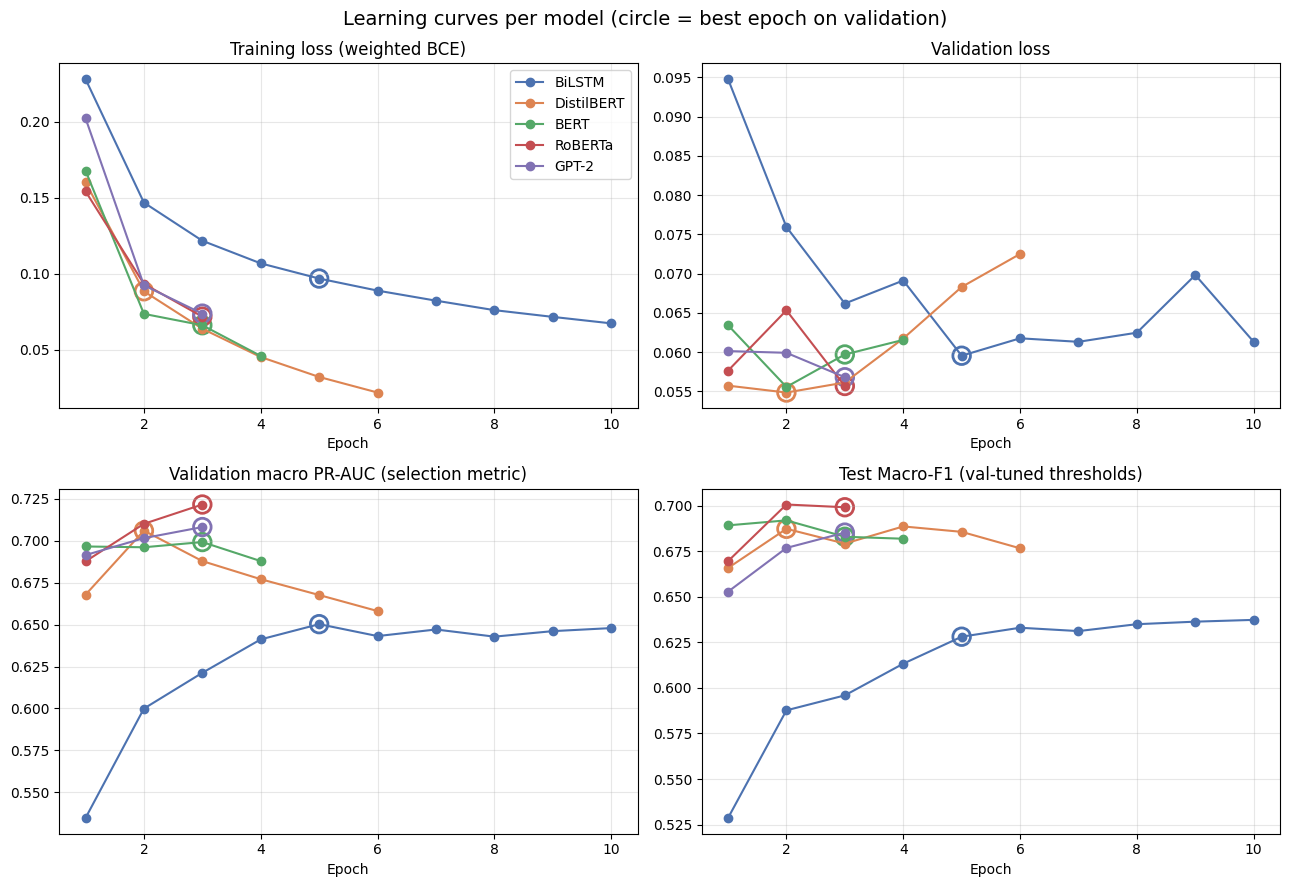

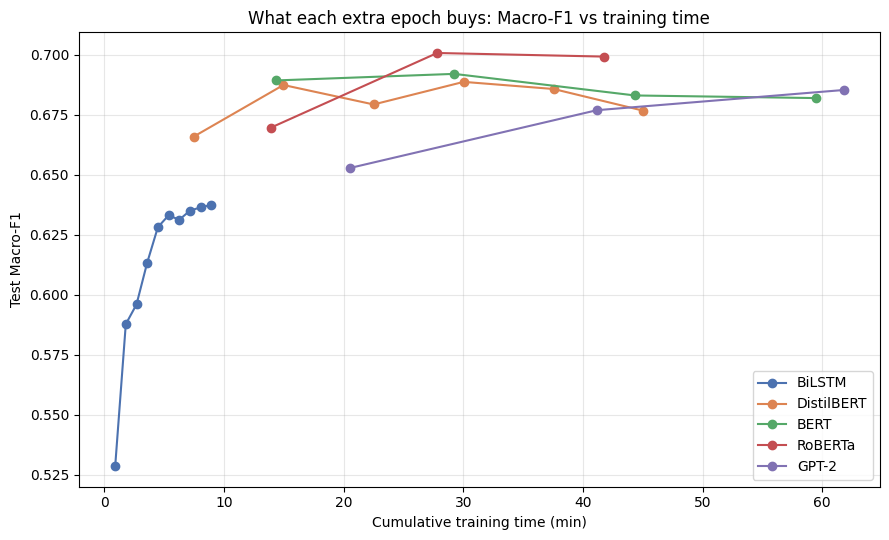

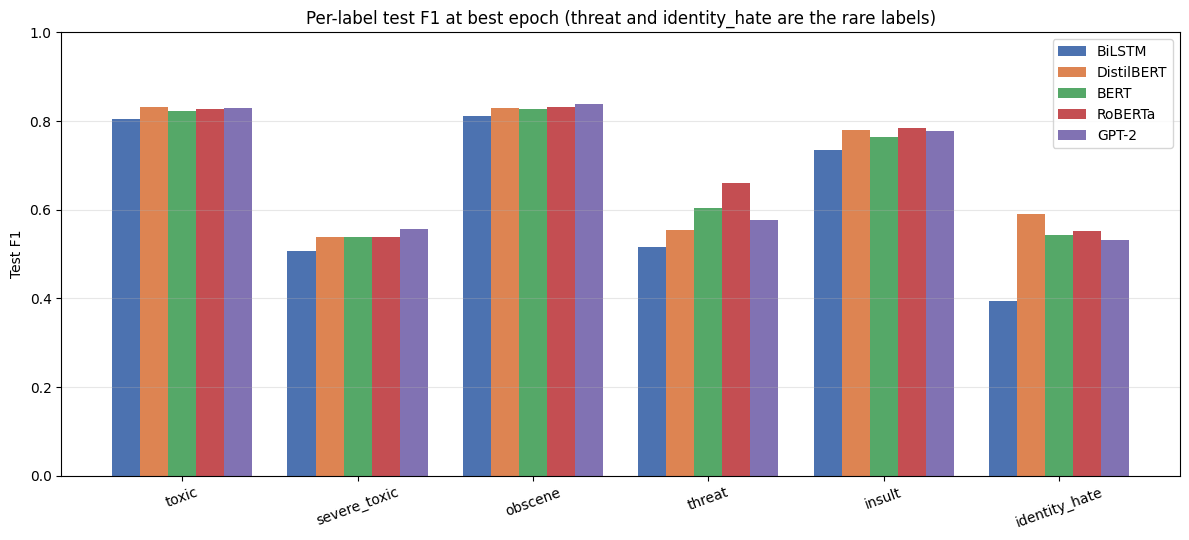

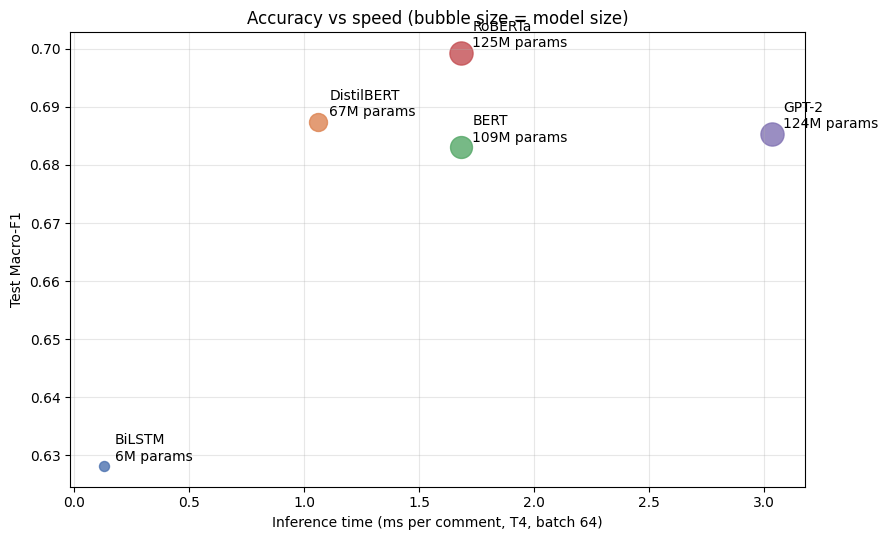

In [15]:
# ---- Figure 1: learning curves ----
panels = [("train_loss", "Training loss (weighted BCE)"), ("val_loss", "Validation loss"),
          ("val_macro_pr_auc", "Validation macro PR-AUC (selection metric)"),
          ("test_macro_f1", "Test Macro-F1 (val-tuned thresholds)")]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title) in zip(axes.ravel(), panels):
    for name, h in histories.items():
        ax.plot(h["epoch"], h[col], marker="o", label=name, color=COLORS[name])
        be = finals[name]["best_epoch"]
        ax.scatter([be], h.loc[h["epoch"] == be, col], s=160, facecolors="none",
                   edgecolors=COLORS[name], linewidths=2)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0, 0].legend()
fig.suptitle("Learning curves per model (circle = best epoch on validation)", fontsize=14)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig1_learning_curves.png", dpi=150); plt.show()

# ---- Figure 2: Macro-F1 vs cumulative training time ----
plt.figure(figsize=(9, 5.5))
for name, h in histories.items():
    plt.plot(h["cumulative_train_time_s"] / 60, h["test_macro_f1"], marker="o", label=name, color=COLORS[name])
plt.xlabel("Cumulative training time (min)"); plt.ylabel("Test Macro-F1")
plt.title("What each extra epoch buys: Macro-F1 vs training time"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig2_f1_vs_training_time.png", dpi=150); plt.show()

# ---- Figure 3: per-label F1 at best epoch ----
names = list(finals); x = np.arange(len(LABELS)); w = 0.8 / len(names)
plt.figure(figsize=(12, 5.5))
for i, name in enumerate(names):
    plt.bar(x + i * w - 0.4 + w / 2, [finals[name]["test"][f"f1_{l}"] for l in LABELS], w,
            label=name, color=COLORS[name])
plt.xticks(x, LABELS, rotation=20); plt.ylabel("Test F1"); plt.ylim(0, 1)
plt.title("Per-label test F1 at best epoch (threat and identity_hate are the rare labels)")
plt.legend(); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig3_per_label_f1.png", dpi=150); plt.show()

# ---- Figure 4: accuracy vs inference speed ----
plt.figure(figsize=(9, 5.5))
for _, r in summary.iterrows():
    plt.scatter(r["Inference (ms/comment)"], r["Test Macro-F1"], s=40 + r["Size (MB)"] / 2,
                color=COLORS[r["Model"]], alpha=0.8)
    plt.annotate(f"{r['Model']}\n{r['Params (M)']:.0f}M params",
                 (r["Inference (ms/comment)"], r["Test Macro-F1"]), xytext=(8, 4), textcoords="offset points")
plt.xlabel("Inference time (ms per comment, T4, batch 64)"); plt.ylabel("Test Macro-F1")
plt.title("Accuracy vs speed (bubble size = model size)"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/fig4_accuracy_vs_speed.png", dpi=150); plt.show()

## 9. Download everything
Creates `toxic_case_study_results.zip` with all tables, figures, per-epoch histories and predictions (it is also already on your Drive).

In [17]:
zip_path = shutil.make_archive(f"/content/toxic_case_study_results{RUN_TAG}", "zip", RESULTS_DIR)
print(f"{zip_path} ({os.path.getsize(zip_path) / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Download did not start automatically:", e,
          "\nOpen the Files panel, right-click the zip and choose Download.")

/content/toxic_case_study_results.zip (14.0 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Troubleshooting
| Problem | What to do |
|---|---|
| **CUDA out of memory** | Set `BATCH_SIZE = 16` (or `MAX_LEN = 96`) in Section 1, then Runtime > Restart session and rerun Sections 1-6. Finished models and finished epochs are kept. |
| **Colab disconnected or the cell was stopped** | Reconnect, rerun Sections 1-6, then rerun 7.0. Each model resumes from its last finished epoch. |
| **`the loss became nan`** | Set `USE_AMP = False`, or halve that model's `lr` in `MODEL_REGISTRY`, then rerun 7.0. |
| **`checkpoint not saved`** | Google Drive is probably full. Free some space, or set `SAVE_CHECKPOINTS = False` (then an interrupted model restarts from epoch 1). |
| **Drive is not usable** | The notebook saves to the session's local disk instead, which is erased at the end of the session. Download the results (Section 9) before leaving. |
| **train.csv not found** | Download `train.csv.zip` from the Kaggle page (accept the competition rules first) and upload it when the file picker appears. The outer Kaggle zip also works. |
| **Warnings about `HF_TOKEN` or unauthenticated requests** | Harmless. You can ignore them. |
| **Train a model again** | Set `FORCE_RETRAIN = True`, run that model, then set it back to `False`. A finished model is skipped even if you change its epochs. |
| **Models trained with different settings** | Keep `SEED`, `MAX_LEN`, `BATCH_SIZE`, `MAX_TRAIN_ROWS` and the epochs the same across sessions, otherwise the comparison is not fair. |
| **Section 8 shows only some models** | That is expected: it compares whatever has finished. |